# Linear Regression

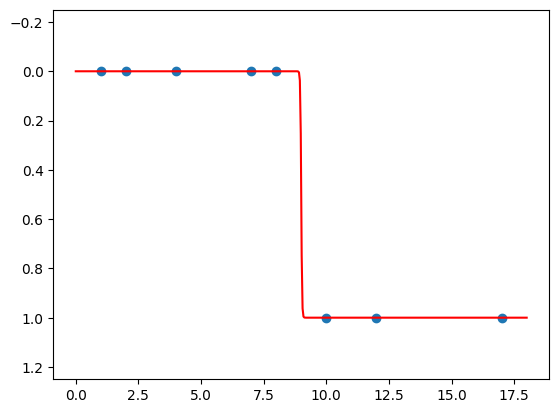

In [3]:
import matplotlib.pyplot as plt
import numpy as np

def transformation(x):
    #return 0.1*x + 0.02
    a = 60
    b = -540
    return 1 / (1 + np.exp(-(a * x + b)))
    
    
X = [1,2,4,7,8,10,12,17] #rozmiary guzów
Y = [0,0,0,0,0,1,1,1] #flaga (decyzja) oceniająca ich złośliwość - 1=złośliwy / 0=niezłośliwy
function_sampling_x_coordinates = np.linspace(0,18,500) #generowanie 500 punktów pomiędzy granicami osi X (0,18) 
function_sampling_y_coordinates = [transformation(x) for x in function_sampling_x_coordinates] #wyznaczanie wartosci funkcji transformation w tych punktach 

plt.plot(X, Y, "o")
plt.plot(function_sampling_x_coordinates, function_sampling_y_coordinates, 'r-')
plt.ylim(bottom = 1.25, top = -0.25)

plt.show()

# Trening klasyfikatora LogisticRegression

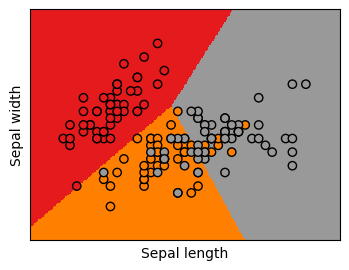

Accuracy: 0.82


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import linear_model, datasets
from helpers_lab2 import plot_boundary

iris = datasets.load_iris()
X = iris.data[:, :2]   #weź tylko dwie cechy przykładowego zbioru
Y = iris.target        # Y to klasy, które chcemy przewidzieć

logreg = linear_model.LogisticRegression(
    C=1.0,
    solver='lbfgs',
    max_iter=200
).fit(X, Y)

plot_boundary(logreg, X, Y)

print("Accuracy:", logreg.score(X, Y))


# Sieci neuronowe

Rozpoznawanie pisma za pomocą sieci neuronowych

[[35  0  0  0  0  0  0  0  0  0]
 [ 0 34  0  0  0  0  0  0  0  0]
 [ 0  0 35  0  0  0  0  0  0  0]
 [ 0  0  0 37  0  0  0  0  0  0]
 [ 0  0  0  0 39  0  0  0  0  0]
 [ 0  0  0  0  1 29  0  0  0  0]
 [ 0  0  0  0  0  0 35  0  0  0]
 [ 0  0  0  0  1  0  0 42  0  1]
 [ 0  1  0  0  0  1  1  0 33  0]
 [ 0  0  0  1  0  0  0  0  0 34]]

errors: 7


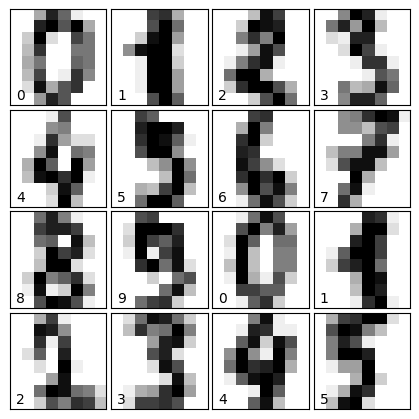

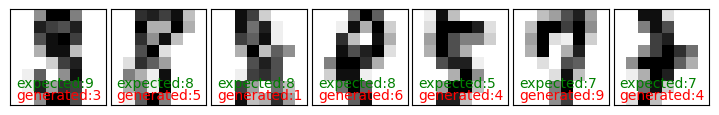

In [2]:
##### import itertools
from sklearn.datasets import load_digits
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report,confusion_matrix
import numpy as np

%matplotlib inline
digits = load_digits() #zbiór zawiera 1797 obrazków reprezentujących cyfry od 0 do 9 (czyli 10 klas decyzyjnych)

fig = plt.figure(figsize = (4,4))
fig.subplots_adjust(left=0, right=1, bottom=0, top=1, hspace=0.05, wspace=0.05)
for i in range(16):
    #wyświetl próbkę 16 obrazków wraz z ich prawdziwymi etykietami
    ax = fig.add_subplot(4, 4, i+1, xticks=[], yticks=[])
    ax.imshow(digits.images[i],cmap=plt.cm.binary,interpolation='nearest')
    ax.text(0, 7, str(digits.target[i]))
    
X_train, X_test, y_train, y_test = train_test_split(digits.data, digits.target, test_size=0.2, random_state=16)

mlp = MLPClassifier(hidden_layer_sizes=(100, 100), max_iter=500, random_state=20)
mlp.fit(X_train, y_train)
predicted = mlp.predict(X_test)

if predicted is not None:
    # Wizualizacja macierzy pomyłek - pokazuje jakie etykiety pomylono z jakimi innymi
    cm = confusion_matrix(y_test,predicted)
    print(cm)

    expected = y_test 
    fig = plt.figure(figsize=(8, 8))  # figure size in inches
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1, hspace=0.05, wspace=0.05)

    # Wizualizacja błędnie zaanotowanych obrazków
    cnt = 0
    for i in range(len(X_test)):
        if predicted[i] == expected[i]:
            continue
        ax = fig.add_subplot(8, 8, cnt + 1, xticks=[], yticks=[])
        ax.imshow(X_test.reshape(-1, 8, 8)[i], cmap=plt.cm.binary, interpolation='nearest')
        cnt += 1

        ax.text(0, 7, "generated:" + str(predicted[i]), color='red')
        ax.text(0, 6, "expected:" + str(expected[i]), color='green')
    print('\nerrors:',cnt)